# Notebook 07 — Stress Testing

Value at Risk estimates potential losses under normal market conditions. Stress testing complements VaR by examining how the portfolio performs during extreme but plausible market events.

This notebook evaluates portfolio performance across several major historical market events, including the COVID-19 market crash, the 2018 equity selloff, the 2022 interest rate shock, and the 2015 China market correction. It also applies a series of hypothetical portfolio shocks to estimate potential losses under severe market conditions.

Together, stress testing and VaR provide a more complete view of portfolio risk.

## Outputs

- Historical stress scenario analysis
- Worst-day losses
- Hypothetical shock analysis
- Stress testing visualizations


Historical Market Stress Scenarios
---------------------------------------------------------------------------
Scenario                   Total Return      Worst Day    99% VaR ($)
---------------------------------------------------------------------------
COVID Crash                     -38.32%        -11.81%        114,488
2018 Selloff                    -19.03%         -3.66%         33,924
2022 Rate Shock                   4.81%         -3.76%         30,354
China Selloff                    -9.28%         -4.10%         40,757
---------------------------------------------------------------------------

Custom Shock Scenarios
---------------------------------------------
Scenario                       Loss ($)
---------------------------------------------
Market Correction               100,000
Severe Drawdown                 200,000
Crisis Scenario                 300,000
Extreme Tail Event              400,000
---------------------------------------------


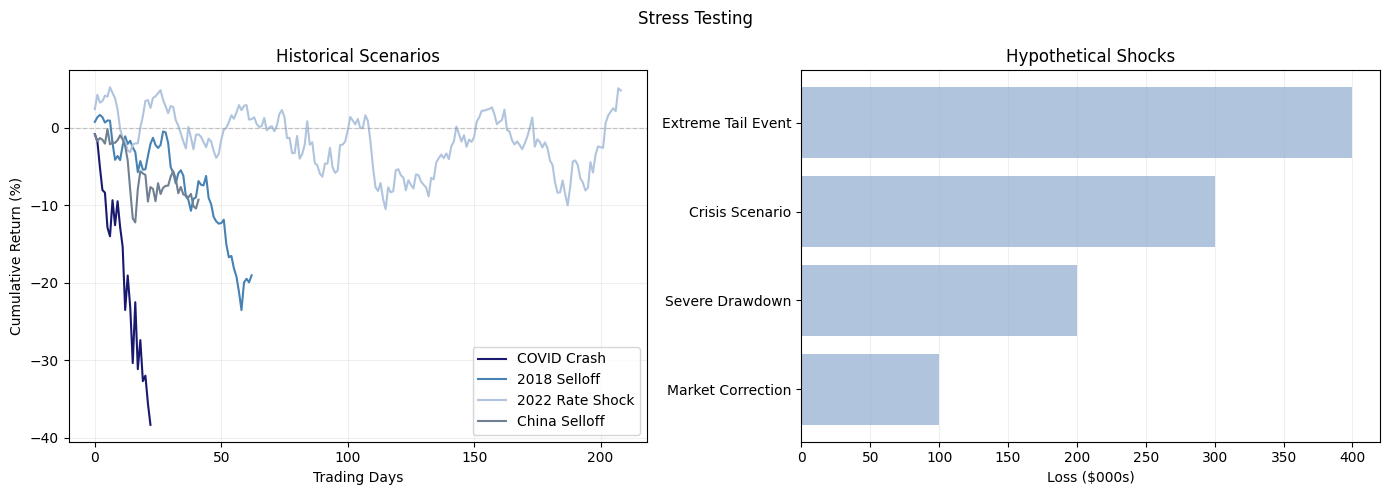

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:.2f}".format)

# Configuration

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
portfolio_value = 1_000_000

# Load Data
log_returns = pd.read_csv( "../data/log_returns.csv",index_col=0,parse_dates=True)

portfolio_returns = log_returns.dot(weights)

# Historical Market Stress Scenarios

scenarios = {
    "COVID Crash": ("2020-02-20", "2020-03-23"),
    "2018 Selloff": ("2018-10-01", "2018-12-31"),
    "2022 Rate Shock": ("2022-01-01", "2022-10-31"),
    "China Selloff": ("2015-08-01", "2015-09-30"),}

print("\nHistorical Market Stress Scenarios")
print("-" * 75)
print(
    f"{'Scenario':<24}"
    f"{'Total Return':>15}"
    f"{'Worst Day':>15}"
    f"{'99% VaR ($)':>15}")
print("-" * 75)

scenario_results = {}

for name, (start, end) in scenarios.items():

    period = portfolio_returns.loc[start:end]

    if len(period) < 10:
        continue

    total_return = (np.exp(period.sum()) - 1) * 100
    worst_day = period.min() * 100
    var_loss = -np.percentile(period, 1) * portfolio_value

    scenario_results[name] = {
        "returns": period,
        "total": total_return,
        "worst_day": worst_day,
        "var": var_loss,}

    print(
        f"{name:<24}"
        f"{total_return:>14.2f}%"
        f"{worst_day:>14.2f}%"
        f"{var_loss:>15,.0f}" )

print("-" * 75)

# Custom Shock Scenarios

shocks = {
    "Market Correction": -0.10,
    "Severe Drawdown": -0.20,
    "Crisis Scenario": -0.30,
    "Extreme Tail Event": -0.40,}

print("\nCustom Shock Scenarios")
print("-" * 45)
print(f"{'Scenario':<24}{'Loss ($)':>15}")
print("-" * 45)

shock_losses = {}

for name, shock in shocks.items():

    loss = abs(shock) * portfolio_value

    shock_losses[name] = loss

    print(
        f"{name:<24}"
        f"{loss:>15,.0f}")

print("-" * 45)

# Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Stress Testing")

colors = [
    "midnightblue",
    "steelblue",
    "lightsteelblue",
    "slategray",]

ax1 = axes[0]
for (name, data), color in zip(scenario_results.items(), colors):
    cumulative = (np.exp(data["returns"].cumsum()) - 1) * 100
    ax1.plot(
        cumulative.values,
        linewidth=1.5,
        color=color,
        label=name,)
ax1.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=0.9,
    alpha=0.4,)
ax1.set_title("Historical Scenarios")
ax1.set_xlabel("Trading Days")
ax1.set_ylabel("Cumulative Return (%)")
ax1.legend()
ax1.grid(alpha=0.2)

ax2 = axes[1]
ax2.barh(
    list(shock_losses.keys()),
    [loss / 1000 for loss in shock_losses.values()],
    color="lightsteelblue",)
ax2.set_title("Hypothetical Shocks")
ax2.set_xlabel("Loss ($000s)")
ax2.grid(axis="x", alpha=0.2)

plt.tight_layout()
os.makedirs("../reports", exist_ok=True)
plt.savefig("../reports/07_stress_testing.png",dpi=150,)
plt.show()

